# Lab 1 · Your first transit fit

A planet crossing its star blocks a little of its light. In this lab you simulate one night of such a transit,
describe the system as a **session**, fit it with nested sampling, and read the result: the planet's size, the
orbit's tilt, the time of mid-transit, and how sure we are of each.

Everything here runs on your computer. Install the package once with
`pip install "git+https://github.com/pearsonkyle/Exoplanet-Science-Lab.git#subdirectory=python"` (add `matplotlib` for the figures).

In [1]:
import numpy as np
import esl
import esl.plot

print("Exoplanet Science Lab", esl.__version__)

Exoplanet Science Lab 0.2.0


## 1. A transit to fit

`esl.transit` is the same light-curve model the website draws. A hot Jupiter with Rp/R★ = 0.14 on a 2.15-day
orbit, seen through a filter where the star's edge is darker than its centre (quadratic limb darkening), observed
for 7 hours every 2 minutes with 1500 ppm of noise per point:

In [2]:
truth = dict(rprs=0.14, ars=8.8, inc=88.0, per=2.15, tmid=0.0)
t = np.arange(-0.15, 0.15, 2 / 1440)                       # days from mid-transit
model = esl.transit(t, dict(truth, ld=[0.40, 0.20], law="quadratic"))
rng = np.random.default_rng(42)
flux = model + rng.normal(0, 0.0015, t.size)
print(f"{t.size} points, transit depth {1e6 * (1 - model.min()):.0f} ppm")

216 points, transit depth 22998 ppm


## 2. Describe the analysis as a session

A **session** holds everything about an analysis: the star, the planet's parameters, the data, which parameters
are free and their priors, and the sampler's settings. The same document opens on the website (Analyze → Save /
Load), so you can move between Python and the browser.

We let three parameters vary: the radius ratio, the inclination and the mid-transit time. The others stay at
their known values.

In [3]:
session = esl.Session(
    name="Simulated hot Jupiter",
    limb_darkening=esl.LimbDarkening(law="quadratic", coefficients=[0.40, 0.20]),
    planets=[esl.Planet(letter="b", parameters=dict(truth, ecc=0.0, omega=0.0))],
    data=esl.Data(light_curve=esl.LightCurve(name="night 1", time=t, flux=flux, flux_err=np.full(t.size, 0.0015))),
    fit=esl.FitSettings(
        free=[
            esl.FreeParameter(key="rprs", prior=esl.Prior.uniform(0.05, 0.25)),
            esl.FreeParameter(key="inc", prior=esl.Prior.uniform(80, 90)),
            esl.FreeParameter(key="tmid", prior=esl.Prior.uniform(-0.02, 0.02)),
        ],
        sampler=esl.Sampler(nlive=300, seed=1),
    ),
)
print(session.summary())

Simulated hot Jupiter
  planets: b
  light curve: 216 points
  limb darkening: quadratic, fixed or sampled coefficients
  free (3): rprs ~ Uniform(0.05, 0.25), inc ~ Uniform(80, 90), tmid ~ Uniform(-0.02, 0.02)
  sampler: 300 live points, seed 1


## 3. Fit

Nested sampling explores the priors and returns the posterior (what the data allow) and the **evidence** ln Z
(how well the model explains the data overall, used later to compare models).

In [4]:
fit = session.run()
print(fit.result.table())

converged: 9925 calls, 0.5 s, ln Z = 1101.381 +- 0.197, chi2 = 166.37 for 216 measurements
  rprs       0.14065 +0.00095 -0.00086
  inc        88.10 +0.15 -0.13
  tmid       -0.00006 +0.00023 -0.00021
  derived:
  t14        0.08606 +0.00039 -0.00041
  emid       1.07494 +0.00021 -0.00022
  ars        8.8
  b          0.291 +0.019 -0.021


Each value is the posterior median with the 68% interval. Compare them with the truth we simulated:

In [5]:
for key in ["rprs", "inc", "tmid"]:
    q = fit.result[key]
    print(f"{key:5s} = {q.median:.5f} +{q.plus:.5f} -{q.minus:.5f}   (truth {truth[key]}, {abs(q.median - truth[key]) / max(q.plus, q.minus):.1f} sigma away)")

rprs  = 0.14065 +0.00095 -0.00086   (truth 0.14, 0.7 sigma away)
inc   = 88.10110 +0.14584 -0.13346   (truth 88.0, 0.7 sigma away)
tmid  = -0.00006 +0.00023 -0.00021   (truth 0.0, 0.3 sigma away)


## 4. Look at it

The data with the best-fitting model and the residuals; then the posterior: each parameter's distribution and
how pairs of parameters trade off (the inclination and the radius ratio are correlated through the transit's shape).

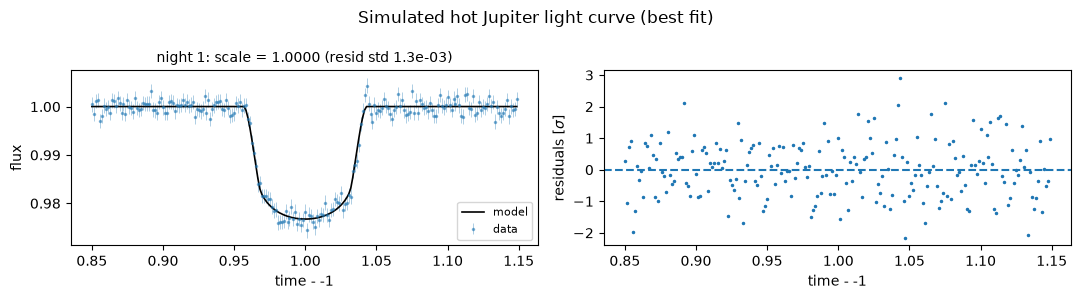

In [6]:
esl.plot.light_curve(fit);

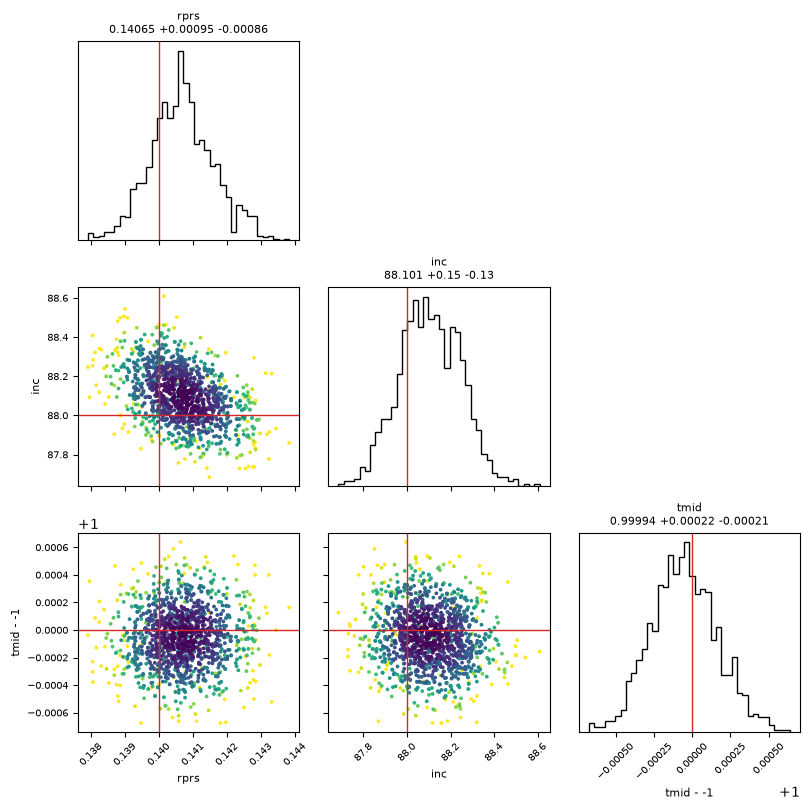

In [7]:
esl.plot.corner(fit, truths={k: truth[k] for k in ["rprs", "inc", "tmid"]});

## 5. What follows from it

Derived quantities come from the posterior draws, with the star's radius and mass (here the defaults of the session):

In [8]:
about = {"depth": "transit depth (fraction of the star's light)", "b": "impact parameter (0 = through the centre)", "t14": "transit duration, days", "rhoStar": "stellar density from a/R* and P, g/cm^3"}
for key, what in about.items():
    d = fit.result.derived.get(key)
    if d is not None:
        print(f"{key:8s} {d.median:.5g} +{d.plus:.2g} -{d.minus:.2g}   {what}")

depth    0.019788 +0.00026 -0.00023   transit depth (fraction of the star's light)
b        0.29149 +0.019 -0.021   impact parameter (0 = through the centre)
t14      0.086062 +0.00039 -0.00041   transit duration, days
rhoStar  2.7887 +0 -0   stellar density from a/R* and P, g/cm^3


## 6. Keep it

`fit.save(...)` writes the session with its result (it opens on the website); `fit.to_markdown()` is a report and
`fit.to_script()` a Python script that rebuilds this analysis line by line.

In [9]:
print(fit.to_markdown()[:900], "…")

# Simulated hot Jupiter

Exoplanet Science Lab 0.2.0 · session format esl-session v1

## System

Limb darkening: quadratic law, coefficients 0.4, 0.2, band TESS (approx.).

| Planet | Rp/R★ | a/R★ | i [°] | P [d] | T mid [d] | e | ω [°] |
| --- | --- | --- | --- | --- | --- | --- | --- |
| b | 0.14 | 8.8 | 88 | 2.15 | 0 | 0 | 0 |

## Data

| Kind | Name | Points | From | To | Median uncertainty | In the fit |
| --- | --- | --- | --- | --- | --- | --- |
| light curve | night 1 | 216 | -0.15 | 0.1486111111 | 0.00150 relative flux | yes |

Times are as given in the data (no conversion between time systems); inside the fit they are measured from 0.

## Fit set-up

| Free parameter | Key | Unit | Prior |
| --- | --- | --- | --- |
| Rp/R★ | `rprs` |  | Uniform(0.05, 0.25) |
| i | `inc` | ° | Uniform(80, 90) |
| T mid | `tmid` | d | Uniform(-0.02, 0.02) |

Sampler: nested sampling (MLFriends re …


**Next:** [Lab 2](./lab02_tess_transit) fits a real TESS transit, starting from the catalogue's values.